# Bài 1 · MLP phân loại chữ số MNIST

        Flatten 784 → 512 → 512 → 10, ReLU và Dropout 0,2 sau hai tầng ẩn.

        Nguồn gồm slide 02 Keras Examples và notebook Keras gốc. MNIST được tải qua torchvision và chuẩn hóa về [0, 1]. Tập validation tách từ 60.000 ảnh train. Tập test chính thức chỉ dùng sau huấn luyện. Môi trường cần torch, torchvision, torchinfo, numpy và matplotlib.

In [1]:
from pathlib import Path
import os
import sys

project = next((path for path in (Path.cwd(), *Path.cwd().parents)
                if (path / 'src/pytorch_core.py').is_file()), None)
if project is None:
    raise FileNotFoundError('Hãy mở notebook từ thư mục KerasToPytorch hoặc notebooks/')
os.chdir(project)
if str(project) not in sys.path:
    sys.path.insert(0, str(project))

In [2]:
import platform
from time import perf_counter

import matplotlib.pyplot as plt
import torch
from torch import nn
from torchinfo import summary

from src.mnist_experiment import (
    make_loaders, plot_curves, read_rows, save_result, use_glorot_initialization,
)
from src.models.mnist_mlp import MNISTMLP
from src.pytorch_core import evaluate, fit, get_device, seed_everything

seed_everything(42)
device = get_device()
if device.type == 'cpu':
    torch.set_num_threads(int(os.environ.get('MNIST_TORCH_THREADS', min(6, os.cpu_count() or 1))))
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | '
      f'{device} | {torch.get_num_threads()} luồng CPU')
train_loader, val_loader, test_loader = make_loaders(batch_size=128, seed=42)
print(f'Train / validation / test: {len(train_loader.dataset):,} / '
      f'{len(val_loader.dataset):,} / {len(test_loader.dataset):,}')
inputs, labels = next(iter(val_loader))
print('Batch:', tuple(inputs.shape), inputs.dtype, tuple(labels.shape), labels.dtype)

Python 3.13.18 | PyTorch 2.15.0+cpu | cpu | 6 luồng CPU
Train / validation / test: 54,000 / 6,000 / 10,000
Batch: (128, 1, 28, 28) torch.float32 (128,) torch.int64


## Mô hình và số tham số

Khởi tạo Glorot uniform và bias 0. CrossEntropyLoss nhận logits và nhãn nguyên.

In [3]:
model = MNISTMLP().apply(use_glorot_initialization)
model = model.to(device)
summary(model, input_size=(1, 1, 28, 28), device=device,
        col_names=('input_size', 'output_size', 'num_params'))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
MNISTMLP                                 [1, 1, 28, 28]            [1, 10]                   --
├─Flatten: 1-1                           [1, 1, 28, 28]            [1, 784]                  --
├─Linear: 1-2                            [1, 784]                  [1, 512]                  401,920
├─ReLU: 1-3                              [1, 512]                  [1, 512]                  --
├─Dropout: 1-4                           [1, 512]                  [1, 512]                  --
├─Linear: 1-5                            [1, 512]                  [1, 512]                  262,656
├─ReLU: 1-6                              [1, 512]                  [1, 512]                  --
├─Dropout: 1-7                           [1, 512]                  [1, 512]                  --
├─Linear: 1-8                            [1, 512]                  [1, 10]                   5,130
Total params: 669,706


Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
MNISTMLP                                 [1, 1, 28, 28]            [1, 10]                   --
├─Flatten: 1-1                           [1, 1, 28, 28]            [1, 784]                  --
├─Linear: 1-2                            [1, 784]                  [1, 512]                  401,920
├─ReLU: 1-3                              [1, 512]                  [1, 512]                  --
├─Dropout: 1-4                           [1, 512]                  [1, 512]                  --
├─Linear: 1-5                            [1, 512]                  [1, 512]                  262,656
├─ReLU: 1-6                              [1, 512]                  [1, 512]                  --
├─Dropout: 1-7                           [1, 512]                  [1, 512]                  --
├─Linear: 1-8                            [1, 512]                  [1, 10]                   5,130
Total params: 669,706


## Huấn luyện 20 epoch

SGD với learning rate 0,01, batch size 128. Thời gian gồm vòng train và validation, đo bằng perf_counter.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
start = perf_counter()
history = fit(model, train_loader, val_loader, criterion, optimizer, device,
              epochs=20, csv_path='logs/history_01_mnist_mlp.csv')
fit_seconds = perf_counter() - start
test = evaluate(model, test_loader, criterion, device)
result = save_result('mlp', model, test, fit_seconds, len(history), device)
print(f"Test loss {result['test_loss']:.4f} | accuracy {result['test_accuracy']:.2%} | "
      f"mốc Keras {result['keras_test_accuracy']:.2%} | "
      f"chênh lệch {result['accuracy_delta_pp']:+.2f} điểm phần trăm")
print(f"Thời gian fit {fit_seconds:.2f} giây | {result['parameters']:,} tham số")

Epoch 01/20 | train 1.3164, accuracy 0.6542 | val 0.6315, accuracy 0.8538 | lr 0.01
Epoch 02/20 | train 0.5714, accuracy 0.8406 | val 0.4266, accuracy 0.8883 | lr 0.01
Epoch 03/20 | train 0.4445, accuracy 0.8729 | val 0.3621, accuracy 0.8973 | lr 0.01
Epoch 04/20 | train 0.3906, accuracy 0.8854 | val 0.3281, accuracy 0.9048 | lr 0.01
Epoch 05/20 | train 0.3581, accuracy 0.8961 | val 0.3049, accuracy 0.9108 | lr 0.01
Epoch 06/20 | train 0.3308, accuracy 0.9043 | val 0.2869, accuracy 0.9172 | lr 0.01
Epoch 07/20 | train 0.3078, accuracy 0.9097 | val 0.2724, accuracy 0.9217 | lr 0.01
Epoch 08/20 | train 0.2948, accuracy 0.9153 | val 0.2598, accuracy 0.9247 | lr 0.01
Epoch 09/20 | train 0.2797, accuracy 0.9195 | val 0.2495, accuracy 0.9278 | lr 0.01
Epoch 10/20 | train 0.2664, accuracy 0.9232 | val 0.2402, accuracy 0.9300 | lr 0.01
Epoch 11/20 | train 0.2543, accuracy 0.9268 | val 0.2316, accuracy 0.9338 | lr 0.01
Epoch 12/20 | train 0.2444, accuracy 0.9294 | val 0.2231, accuracy 0.9352 | 

## Đường cong huấn luyện

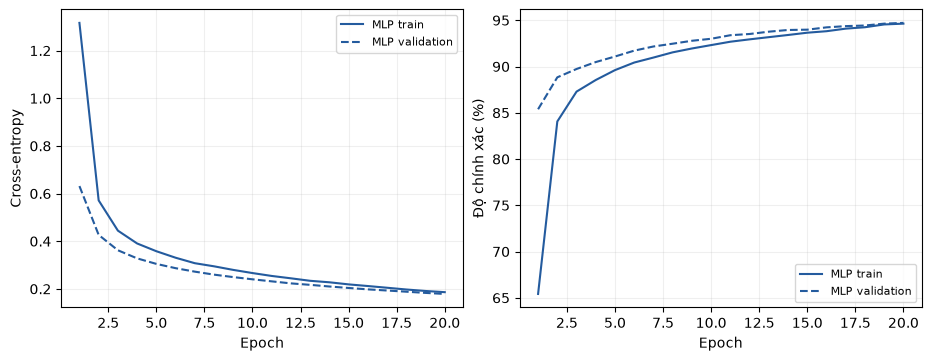

In [5]:
plot_curves({'MLP': history}, 'figures/01_mnist_mlp_curves.png')
plt.show()

## Dự đoán một ảnh test

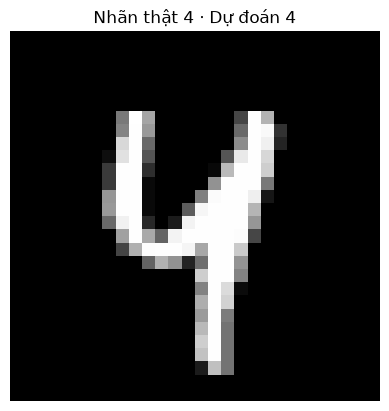

In [6]:
sample, actual = test_loader.dataset[42]
with torch.inference_mode():
    probabilities = model(sample.unsqueeze(0).to(device)).softmax(dim=1)
predicted = probabilities.argmax(dim=1).item()
plt.imshow(sample.squeeze(0), cmap='gray')
plt.title(f'Nhãn thật {actual.item()} · Dự đoán {predicted}')
plt.axis('off')
plt.show()

## Thử nghiệm bổ sung · Chuẩn hóa theo tập train

Thử cấu hình cùng kiến trúc, batch size, optimizer và 20 epoch, với điểm ảnh được trừ trung bình và chia độ lệch chuẩn tính trên tập train. Validation và test dùng lại thống kê đó. CSV của cấu hình này có hậu tố _standardized. Notebook CNN dùng kết quả MLP chuẩn hóa [0, 1] ở trên để so sánh với cùng tiền xử lý.

In [7]:
seed_everything(42)
train_std, val_std, test_std = make_loaders(batch_size=128, seed=42, standardize=True)
model_std = MNISTMLP().apply(use_glorot_initialization).to(device)
optimizer_std = torch.optim.SGD(model_std.parameters(), lr=0.01)
start_std = perf_counter()
history_std = fit(
    model_std, train_std, val_std, criterion, optimizer_std, device, epochs=20,
    csv_path='logs/history_01_mnist_mlp_standardized.csv',
)
seconds_std = perf_counter() - start_std
test_scores_std = evaluate(model_std, test_std, criterion, device)
result_std = save_result(
    'mlp', model_std, test_scores_std, seconds_std, len(history_std), device,
    variant='standardized',
)
print(f"Validation {history_std[-1]['val_accuracy']:.2%} | "
      f"test {result_std['test_accuracy']:.2%} | "
      f"chênh lệch mốc Keras {result_std['accuracy_delta_pp']:+.2f} điểm phần trăm")

Epoch 01/20 | train 0.6946, accuracy 0.7895 | val 0.3371, accuracy 0.9020 | lr 0.01
Epoch 02/20 | train 0.3603, accuracy 0.8920 | val 0.2726, accuracy 0.9182 | lr 0.01
Epoch 03/20 | train 0.2984, accuracy 0.9112 | val 0.2381, accuracy 0.9290 | lr 0.01
Epoch 04/20 | train 0.2602, accuracy 0.9212 | val 0.2143, accuracy 0.9362 | lr 0.01
Epoch 05/20 | train 0.2333, accuracy 0.9317 | val 0.1974, accuracy 0.9418 | lr 0.01
Epoch 06/20 | train 0.2118, accuracy 0.9381 | val 0.1844, accuracy 0.9460 | lr 0.01
Epoch 07/20 | train 0.1972, accuracy 0.9416 | val 0.1737, accuracy 0.9487 | lr 0.01
Epoch 08/20 | train 0.1845, accuracy 0.9445 | val 0.1656, accuracy 0.9508 | lr 0.01
Epoch 09/20 | train 0.1717, accuracy 0.9486 | val 0.1575, accuracy 0.9533 | lr 0.01
Epoch 10/20 | train 0.1628, accuracy 0.9520 | val 0.1499, accuracy 0.9553 | lr 0.01
Epoch 11/20 | train 0.1522, accuracy 0.9546 | val 0.1448, accuracy 0.9565 | lr 0.01
Epoch 12/20 | train 0.1454, accuracy 0.9565 | val 0.1390, accuracy 0.9582 | 